In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import nltk

print("Everything is working!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Everything is working!
Pandas: 3.0.6
NumPy: 2.4.6
Scikit-learn: 1.9.1


In [7]:
import pandas as pd

spam_df = pd.read_csv(
    r"C:\Users\sarik\Desktop\Spam-Toxic-Detection\data\spam.csv",
    encoding="latin-1"
)

spam_df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [8]:
spam_df.shape

(5572, 5)

In [9]:
spam_df.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')

In [10]:
spam_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [11]:
spam_df.isnull().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

In [12]:
spam_df.isnull().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

In [13]:
spam_df.iloc[:, 0].value_counts()

v1
ham     4825
spam     747
Name: count, dtype: int64

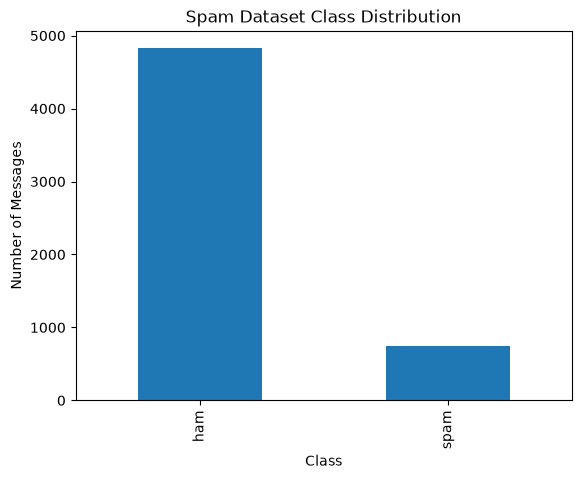

In [14]:
spam_df.iloc[:, 0].value_counts().plot(kind="bar")
plt.title("Spam Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Messages")
plt.show()

In [15]:
spam_df = spam_df.rename(columns={
    "v1": "label",
    "v2": "text"
})

spam_df.head()

,label,text,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [18]:
spam_df = spam_df[["label", "text"]]

spam_df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [19]:
spam_df.isnull().sum()

label    0
text     0
dtype: int64

In [20]:
spam_df = spam_df.dropna()

In [21]:
spam_df.duplicated().sum()

np.int64(403)

In [22]:
spam_df = spam_df.drop_duplicates()

In [23]:
spam_df.duplicated().sum()

np.int64(0)

In [24]:
spam_df["label"].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

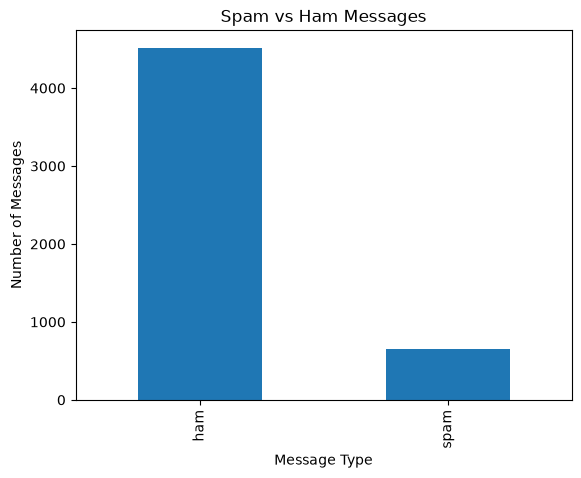

In [25]:
import matplotlib.pyplot as plt

spam_df["label"].value_counts().plot(kind="bar")

plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

In [26]:
spam_df["text_length"] = spam_df["text"].apply(len)

spam_df.head()

,label,text,text_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [27]:
spam_df["text_length"].describe()

count    5169.000000
mean       78.977945
std        58.236293
min         2.000000
25%        36.000000
50%        60.000000
75%       117.000000
max       910.000000
Name: text_length, dtype: float64

In [28]:
spam_df.groupby("label")["text_length"].mean()

label
ham      70.459256
spam    137.891271
Name: text_length, dtype: float64

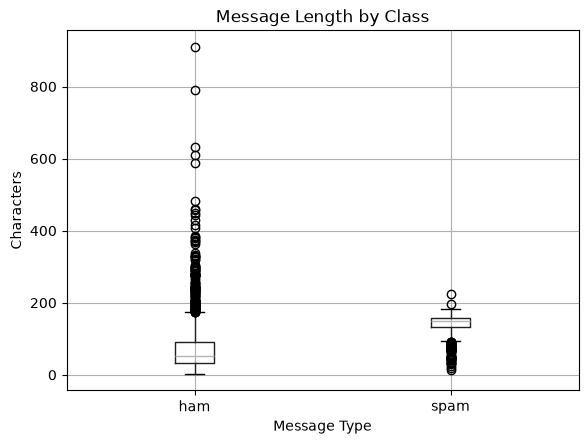

In [29]:
spam_df.boxplot(
    column="text_length",
    by="label"
)

plt.title("Message Length by Class")
plt.suptitle("")
plt.xlabel("Message Type")
plt.ylabel("Characters")
plt.show()

In [30]:
spam_df[spam_df["label"] == "ham"]["text"].head(10)

0     Go until jurong point, crazy.. Available only ...
1                         Ok lar... Joking wif u oni...
3     U dun say so early hor... U c already then say...
4     Nah I don't think he goes to usf, he lives aro...
6     Even my brother is not like to speak with me. ...
7     As per your request 'Melle Melle (Oru Minnamin...
10    I'm gonna be home soon and i don't want to tal...
13    I've been searching for the right words to tha...
14                  I HAVE A DATE ON SUNDAY WITH WILL!!
16                           Oh k...i'm watching here:)
Name: text, dtype: str

In [31]:
spam_df[spam_df["label"] == "spam"]["text"].head(10)

2     Free entry in 2 a wkly comp to win FA Cup fina...
5     FreeMsg Hey there darling it's been 3 week's n...
8     WINNER!! As a valued network customer you have...
9     Had your mobile 11 months or more? U R entitle...
11    SIX chances to win CASH! From 100 to 20,000 po...
12    URGENT! You have won a 1 week FREE membership ...
15    XXXMobileMovieClub: To use your credit, click ...
19    England v Macedonia - dont miss the goals/team...
34    Thanks for your subscription to Ringtone UK yo...
42    07732584351 - Rodger Burns - MSG = We tried to...
Name: text, dtype: str

In [32]:
import nltk

nltk.download("stopwords")
nltk.download("punkt")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sarik\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sarik\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [33]:
import re
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print(list(stop_words)[:20])

['all', 'do', 'but', 'she', "should've", 'their', 'can', "he'd", 'himself', 'under', 'why', 'by', 'o', "shouldn't", 'no', 'wasn', 'my', 'same', 'on', "they'll"]


In [34]:
def clean_text(text):
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    
    # Remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]
    
    return " ".join(words)

In [35]:
sample = spam_df["text"].iloc[0]

print("Original:")
print(sample)

print("\nCleaned:")
print(clean_text(sample))

Original:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Cleaned:
go jurong point crazy available bugis n great world la e buffet cine got amore wat


In [36]:
spam_df["clean_text"] = spam_df["text"].apply(clean_text)

In [37]:
spam_df[["text", "clean_text"]].head(10)

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling weeks word back id like fu...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months u r entitled update latest colou...


In [38]:
spam_df["clean_text"].isnull().sum()


np.int64(0)

In [39]:
(spam_df["clean_text"].str.strip() == "").sum()

np.int64(6)

In [41]:
spam_df = spam_df[spam_df["clean_text"].str.strip() != ""]

In [42]:
from collections import Counter

all_words = " ".join(spam_df["clean_text"]).split()

word_counts = Counter(all_words)

word_counts.most_common(20)

[('u', 1020),
 ('call', 490),
 ('im', 459),
 ('get', 366),
 ('ur', 316),
 ('go', 272),
 ('dont', 269),
 ('ltgt', 254),
 ('ok', 251),
 ('free', 245),
 ('know', 239),
 ('got', 232),
 ('like', 231),
 ('good', 217),
 ('ill', 210),
 ('come', 210),
 ('time', 199),
 ('day', 191),
 ('want', 187),
 ('love', 178)]

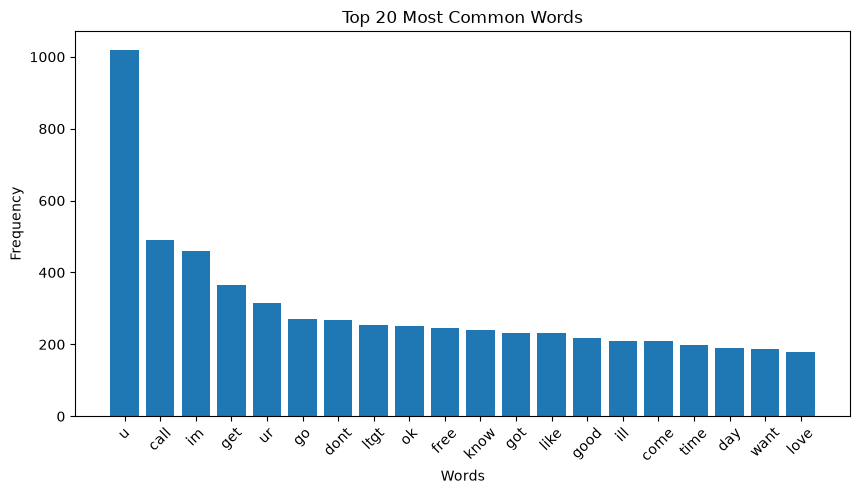

In [43]:
common_words = word_counts.most_common(20)

words = [item[0] for item in common_words]
counts = [item[1] for item in common_words]

plt.figure(figsize=(10, 5))

plt.bar(words, counts)

plt.xticks(rotation=45)
plt.title("Top 20 Most Common Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.show()

In [44]:
spam_df.to_csv(
    "../data/spam_cleaned.csv",
    index=False
)

In [45]:
X = spam_df["clean_text"]
y = spam_df["label"]

In [46]:
print(X.head())
print(y.head())

0    go jurong point crazy available bugis n great ...
1                              ok lar joking wif u oni
2    free entry wkly comp win fa cup final tkts st ...
3                  u dun say early hor u c already say
4          nah dont think goes usf lives around though
Name: clean_text, dtype: str
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: str


In [47]:
y = y.map({
    "ham": 0,
    "spam": 1
})

In [48]:
y.value_counts()

label
0    4510
1     653
Name: count, dtype: int64

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

In [51]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("Training:", X_train_tfidf.shape)
print("Testing:", X_test_tfidf.shape)

Training: (4130, 5000)
Testing: (1033, 5000)


In [52]:
tfidf.fit_transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 35759 stored elements and shape (4130, 5000)>

In [54]:
from sklearn.naive_bayes import MultinomialNB
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3608., 522.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.14,-2.07]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 5000)","[[1.4 ,1.84,3.28,...,0.9 ,1.28,0. ], [0. ,0. ,0. ,...,0. ,0. ,0.74]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 5000)","[[-8.67,-8.5 ,-8.09,...,-8.9 ,-8.72,-9.54], [-8.86,-8.86,-8.86,...,-8.86,-8.86,-8.31]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5000


In [55]:
y_pred = nb_model.predict(X_test_tfidf)
print(y_pred[:20])

[1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [56]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.968054211035818


In [57]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"]
    )
)

              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       902
        Spam       0.99      0.76      0.86       131

    accuracy                           0.97      1033
   macro avg       0.98      0.88      0.92      1033
weighted avg       0.97      0.97      0.97      1033



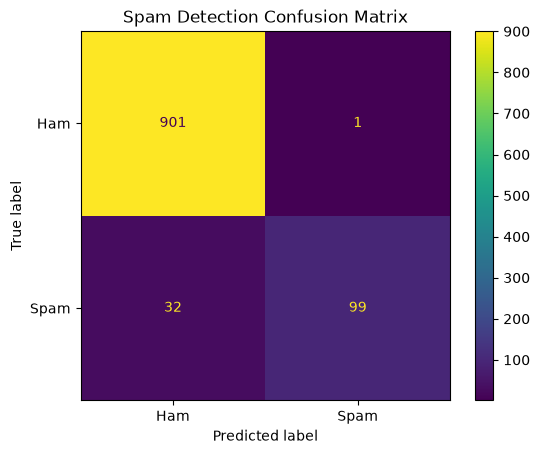

In [58]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()

plt.title("Spam Detection Confusion Matrix")
plt.show()

In [59]:
test_messages = [
    "Hey, are we meeting today at 5 pm?",
    "Congratulations! You have won a free prize. Click now!",
    "Can you send me the assignment?",
    "URGENT! Claim your cash reward by clicking this link!"
]

In [60]:
clean_messages = [
    clean_text(message)
    for message in test_messages
]

In [61]:
message_tfidf = tfidf.transform(clean_messages)
predictions = nb_model.predict(message_tfidf)
for message, prediction in zip(test_messages, predictions):
    result = "SPAM" if prediction == 1 else "HAM"
    
    print("Message:", message)
    print("Prediction:", result)
    print("-" * 60)

Message: Hey, are we meeting today at 5 pm?
Prediction: HAM
------------------------------------------------------------
Message: Congratulations! You have won a free prize. Click now!
Prediction: SPAM
------------------------------------------------------------
Message: Can you send me the assignment?
Prediction: HAM
------------------------------------------------------------
Message: URGENT! Claim your cash reward by clicking this link!
Prediction: SPAM
------------------------------------------------------------


In [62]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(
    max_iter=1000
)
lr_model.fit(X_train_tfidf, y_train)
lr_pred = lr_model.predict(X_test_tfidf)
print(classification_report(
    y_test,
    lr_pred,
    target_names=["Ham", "Spam"]
))
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy)

              precision    recall  f1-score   support

         Ham       0.95      1.00      0.97       902
        Spam       0.98      0.64      0.77       131

    accuracy                           0.95      1033
   macro avg       0.96      0.82      0.87      1033
weighted avg       0.95      0.95      0.95      1033

Logistic Regression Accuracy: 0.952565343659245


In [63]:
from sklearn.svm import LinearSVC
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)
svm_pred = svm_model.predict(X_test_tfidf)
print(classification_report(
    y_test,
    svm_pred,
    target_names=["Ham", "Spam"]
))
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svm_accuracy)

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       902
        Spam       1.00      0.87      0.93       131

    accuracy                           0.98      1033
   macro avg       0.99      0.94      0.96      1033
weighted avg       0.98      0.98      0.98      1033

SVM Accuracy: 0.9835430784123911


In [64]:
nb_accuracy = accuracy_score(y_test, y_pred)

results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Linear SVM"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy
    ]
})

results

,Model,Accuracy
0,Naive Bayes,0.968054
1,Logistic Regression,0.952565
2,Linear SVM,0.983543


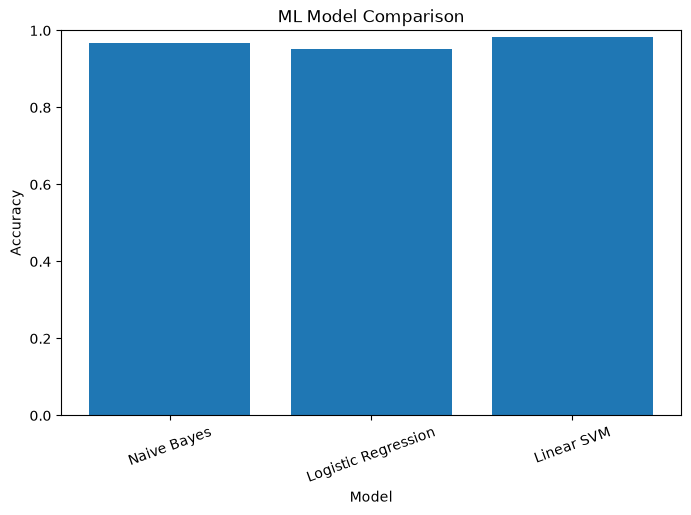

In [65]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("ML Model Comparison")

plt.xticks(rotation=20)
plt.show()

In [66]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_results = []

models = {
    "Naive Bayes": y_pred,
    "Logistic Regression": lr_pred,
    "Linear SVM": svm_pred
}

for name, predictions in models.items():
    
    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(model_results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.968054,0.990000,0.755725,0.857143
1,Logistic Regression,0.952565,0.976744,0.641221,0.774194
2,Linear SVM,0.983543,1.000000,0.870229,0.930612


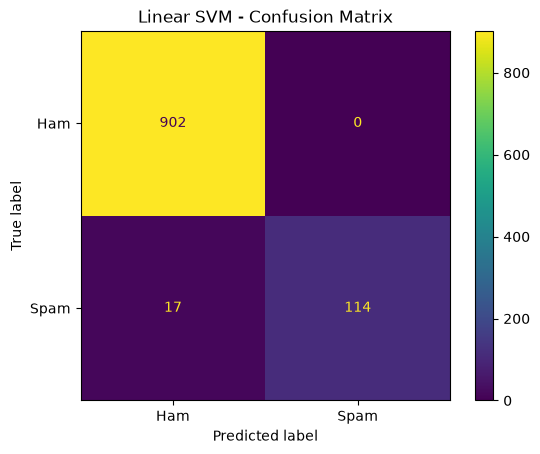

In [67]:
cm = confusion_matrix(y_test, svm_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()

plt.title("Linear SVM - Confusion Matrix")
plt.show()

In [68]:
test_messages = [
    "Hello, how are you doing today?",
    "Congratulations! You have won a free iPhone. Click now!",
    "Please send me the project report.",
    "URGENT! Claim your reward immediately!"
]

In [69]:
clean_messages = [
    clean_text(message)
    for message in test_messages
]

In [70]:
message_tfidf = tfidf.transform(clean_messages)

In [71]:
predictions = svm_model.predict(message_tfidf)

In [72]:
for message, prediction in zip(test_messages, predictions):

    result = "SPAM" if prediction == 1 else "HAM"

    print(f"Message: {message}")
    print(f"Prediction: {result}")
    print("-" * 60)

Message: Hello, how are you doing today?
Prediction: HAM
------------------------------------------------------------
Message: Congratulations! You have won a free iPhone. Click now!
Prediction: SPAM
------------------------------------------------------------
Message: Please send me the project report.
Prediction: HAM
------------------------------------------------------------
Message: URGENT! Claim your reward immediately!
Prediction: SPAM
------------------------------------------------------------


In [73]:
import joblib

In [74]:
joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

['../models/tfidf_vectorizer.pkl']

In [75]:
joblib.dump(
    svm_model,
    "../models/spam_model.pkl"
)

['../models/spam_model.pkl']

In [78]:
import joblib

loaded_model = joblib.load(
    r"C:\Users\sarik\Desktop\Spam-Toxic-Detection\models\spam_model.pkl"
)

loaded_tfidf = joblib.load(
    r"C:\Users\sarik\Desktop\Spam-Toxic-Detection\models\tfidf_vectorizer.pkl"
)

print("Model and TF-IDF loaded successfully!")

Model and TF-IDF loaded successfully!


In [79]:
new_message = "Congratulations! You won a free prize!"

cleaned = clean_text(new_message)

vector = loaded_tfidf.transform([cleaned])

prediction = loaded_model.predict(vector)[0]

if prediction == 1:
    print("SPAM")
else:
    print("HAM")

SPAM
